# 🚗 Car Price Prediction with Machine Learning

### Regression Project | Used-Car Pricing

This project predicts the **selling price of a used car** from vehicle and sales-related features.

**Business goal:** provide a fast, data-driven price benchmark that can support used-car dealers, buyers, and sellers during pricing decisions.

**Dataset:** [Kaggle – Vehicle Dataset from CarDekho](https://www.kaggle.com/datasets/nehalbirla/vehicle-dataset-from-cardekho)

**Price unit:** INR lakh (1 lakh = 100,000 Indian rupees). All price results and error metrics use this unit.

> The dataset is small, so this project is designed as a clean **portfolio / learning project**, not as a production pricing system

## 1. Import Libraries

We use:
- **Pandas / NumPy** for data handling
- **Matplotlib** for visualization
- **Scikit-learn** for preprocessing, modeling, and evaluation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", 50)


## 2. Load Dataset

In [2]:
df = pd.read_csv("car_prediction_data.csv")
df.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


## 3. Data Overview

The dataset contains **301 vehicles and 9 original columns**

| Column | Meaning |
|---|---|
| `Car_Name` | Car model |
| `Year` | Manufacturing year |
| `Selling_Price` | Used-car selling price (INR lakh) — target |
| `Present_Price` | Present showroom price (INR lakh) |
| `Kms_Driven` | Kilometers driven |
| `Fuel_Type` | Petrol, Diesel, or CNG |
| `Seller_Type` | Dealer or Individual |
| `Transmission` | Manual or Automatic |
| `Owner` | Number of previous owners |

In [3]:
print("Shape:", df.shape)
print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing"))

print("\nExact duplicate rows:", df.duplicated().sum())
print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

Shape: (301, 9)

Missing values:


,Missing
Car_Name,0
Year,0
Selling_Price,0
Present_Price,0
Kms_Driven,0
Fuel_Type,0
Seller_Type,0
Transmission,0
Owner,0



Exact duplicate rows: 2

Data types:


,Data Type
Car_Name,str
Year,int64
Selling_Price,float64
Present_Price,float64
Kms_Driven,int64
Fuel_Type,str
Seller_Type,str
Transmission,str
Owner,int64


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Year,301.0,2013.627907,2.891554,2003.00,2012.0,2014.0,2016.0,2018.0
Selling_Price,301.0,4.661296,5.082812,0.10,0.9,3.6,6.0,35.0
Present_Price,301.0,7.628472,8.644115,0.32,1.2,6.4,9.9,92.6
Kms_Driven,301.0,36947.205980,38886.883882,500.00,15000.0,32000.0,48767.0,500000.0
Owner,301.0,0.043189,0.247915,0.00,0.0,0.0,0.0,3.0


### Quick categorical check

This helps us understand the distribution of the main categorical features before modeling

**Note:** Exact duplicate rows are reported, but not automatically removed: the data does not include a unique listing ID, so we cannot verify whether they represent repeated records or separate listings

In [5]:
for col in ["Fuel_Type", "Seller_Type", "Transmission"]:
    print(f"\n{col}")
    display(df[col].value_counts().to_frame("Count"))


Fuel_Type


,Count
Fuel_Type,
Petrol,239
Diesel,60
CNG,2



Seller_Type


,Count
Seller_Type,
Dealer,195
Individual,106



Transmission


,Count
Transmission,
Manual,261
Automatic,40


## 4. Exploratory Data Analysis

We focus only on visuals that help explain the pricing problem

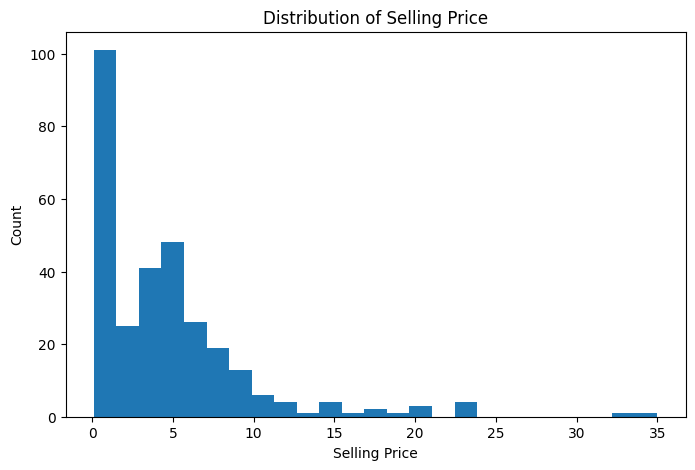

In [6]:
plt.figure(figsize=(8, 5))
plt.hist(df["Selling_Price"], bins=25)
plt.title("Distribution of Selling Price")
plt.xlabel("Selling Price")
plt.ylabel("Count")
plt.show()

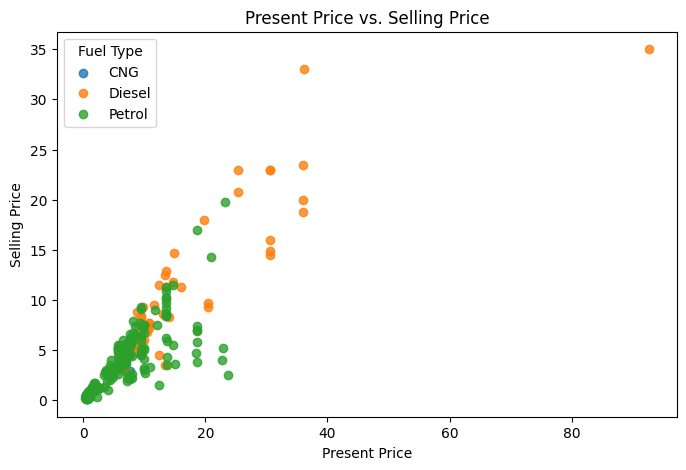

In [7]:
plt.figure(figsize=(8, 5))

for fuel_type, group in df.groupby("Fuel_Type"):
    plt.scatter(
        group["Present_Price"],
        group["Selling_Price"],
        label=fuel_type,
        alpha=0.8
    )

plt.title("Present Price vs. Selling Price")
plt.xlabel("Present Price")
plt.ylabel("Selling Price")
plt.legend(title="Fuel Type")
plt.show()

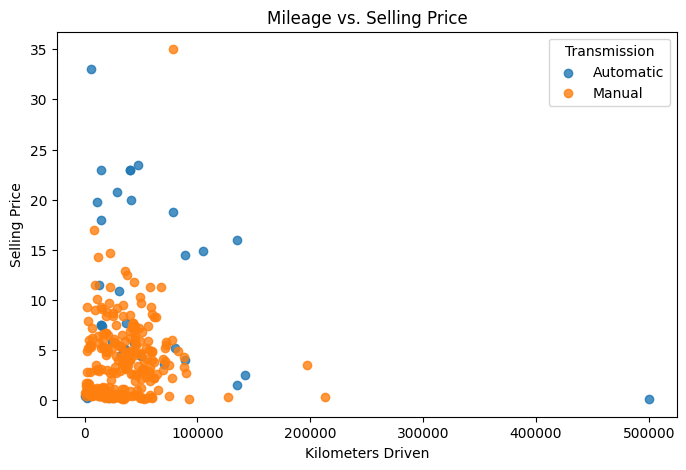

In [8]:
plt.figure(figsize=(8, 5))

for transmission, group in df.groupby("Transmission"):
    plt.scatter(
        group["Kms_Driven"],
        group["Selling_Price"],
        label=transmission,
        alpha=0.8
    )

plt.title("Mileage vs. Selling Price")
plt.xlabel("Kilometers Driven")
plt.ylabel("Selling Price")
plt.legend(title="Transmission")
plt.show()

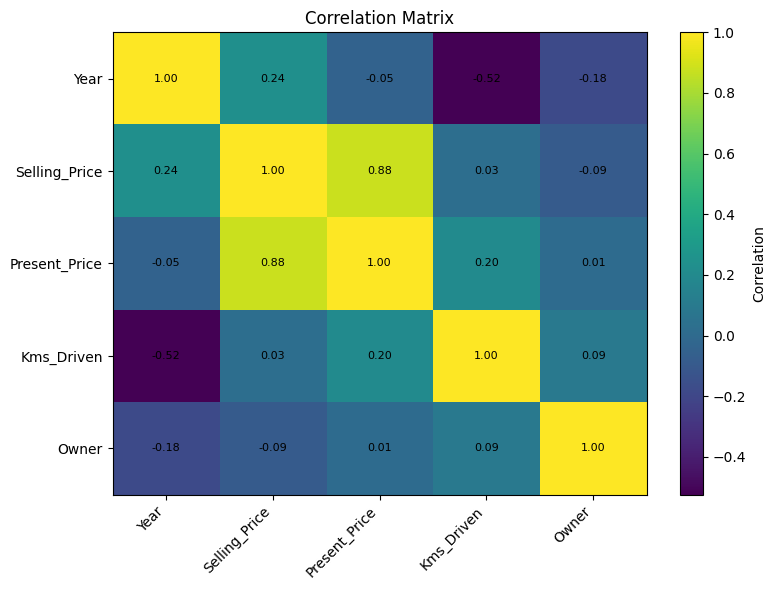

In [9]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(8, 6))
plt.imshow(corr, aspect="auto")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr.index)), corr.index)

for i in range(len(corr.index)):
    for j in range(len(corr.columns)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)

plt.title("Correlation Matrix")
plt.colorbar(label="Correlation")
plt.tight_layout()
plt.show()

### EDA observations

- `Present_Price` has a strong relationship with `Selling_Price`.
- Vehicle age and mileage are also relevant for resale value.
- Fuel type, seller type, and transmission may add additional information.
- `Car_Name` has many unique values compared with the small dataset, so we do **not** use it in the first model to reduce overfitting risk.

## 5. Feature Engineering

Instead of using the manufacturing year directly, we create **Vehicle_Age**.

The newest manufacturing year in this dataset is **2018**. We use **2019** as a fixed historical reference, rather than calculating age relative to today. `Vehicle_Age` therefore describes age at that reference point, not current vehicle age.

In [10]:
REFERENCE_YEAR = df["Year"].max() + 1

df["Vehicle_Age"] = REFERENCE_YEAR - df["Year"]

df[["Year", "Vehicle_Age"]].head()

,Year,Vehicle_Age
0,2014,5
1,2013,6
2,2017,2
3,2011,8
4,2014,5


## 6. Prepare Features and Target

**Target (`y`)**: `Selling_Price`

**Features (`X`)**:
- Present price
- Kilometers driven
- Ownership history
- Vehicle age
- Fuel type
- Seller type
- Transmission

In [11]:
features = [
    "Present_Price",
    "Kms_Driven",
    "Owner",
    "Vehicle_Age",
    "Fuel_Type",
    "Seller_Type",
    "Transmission"
]

X = df[features]
y = df["Selling_Price"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Training set: (240, 7)
Test set: (61, 7)


## 7. Preprocessing Pipeline

Numerical features are standardized and categorical features are converted with **One-Hot Encoding**.

Using a pipeline keeps preprocessing and modeling together and helps prevent inconsistent transformations.

In [12]:
numeric_features = [
    "Present_Price",
    "Kms_Driven",
    "Owner",
    "Vehicle_Age"
]

categorical_features = [
    "Fuel_Type",
    "Seller_Type",
    "Transmission"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            categorical_features
        )
    ]
)

## 8. Model Comparison

We compare four regression algorithms:

- Linear Regression
- Decision Tree
- Random Forest
- Gradient Boosting

For a more reliable comparison, the training data is evaluated with **5-fold cross-validation** using **MAE, RMSE, and R²**

In [13]:
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(
        max_depth=5,
        random_state=42
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        random_state=42
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    )
}

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for name, model in models.items():
    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "RMSE": "neg_root_mean_squared_error",
            "R2": "r2"
        }
    )

    results.append({
        "Model": name,
        "CV_MAE": -scores["test_MAE"].mean(),
        "CV_RMSE": -scores["test_RMSE"].mean(),
        "CV_R2": scores["test_R2"].mean()
    })

results_df = (
    pd.DataFrame(results)
    .sort_values("CV_R2", ascending=False)
    .reset_index(drop=True)
)

results_df.round(3)

,Model,CV_MAE,CV_RMSE,CV_R2
0,Gradient Boosting,0.645,1.389,0.924
1,Random Forest,0.714,1.571,0.904
2,Decision Tree,0.937,2.077,0.831
3,Linear Regression,1.332,2.230,0.801


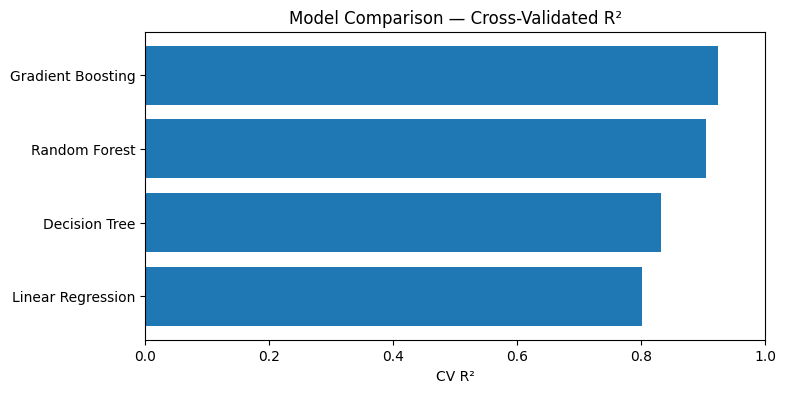

In [14]:
plot_df = results_df.sort_values("CV_R2")

plt.figure(figsize=(8, 4))
plt.barh(plot_df["Model"], plot_df["CV_R2"])
plt.title("Model Comparison — Cross-Validated R²")
plt.xlabel("CV R²")
plt.xlim(0, 1)
plt.show()

## 9. Train the Best Model

The model with the highest cross-validated R² is selected automatically and then evaluated once on the untouched test set.

*MAE and RMSE below are measured in INR lakh.*

In [15]:
best_model_name = results_df.loc[0, "Model"]
best_model = models[best_model_name]

best_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", best_model)
    ]
)

best_pipeline.fit(X_train, y_train)
y_pred = best_pipeline.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Best Model:", best_model_name)
print(f"MAE : {mae:.3f} INR lakh")
print(f"RMSE: {rmse:.3f} INR lakh")
print(f"R²  : {r2:.3f}")

Best Model: Gradient Boosting
MAE : 0.564 INR lakh
RMSE: 0.860 INR lakh
R²  : 0.968


### Actual vs. Predicted Prices

A strong model should place most points close to the diagonal reference line.

Both axes show prices in **INR lakh**.

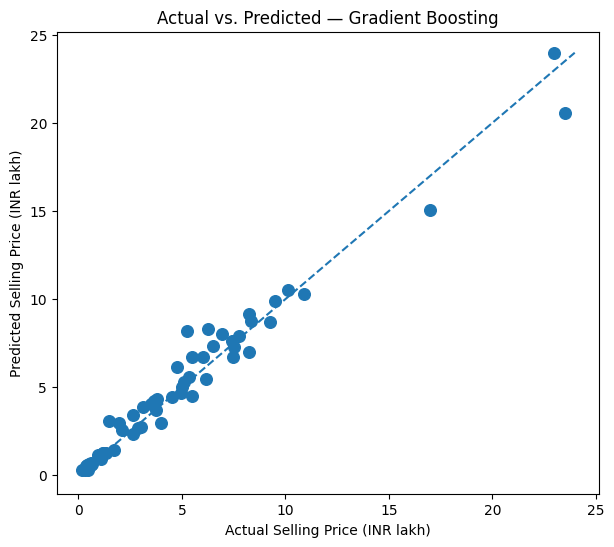

In [16]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, s=70)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.title(f"Actual vs. Predicted — {best_model_name}")
plt.xlabel("Actual Selling Price (INR lakh)")
plt.ylabel("Predicted Selling Price (INR lakh)")
plt.show()

### Residual Analysis

Residual = actual price − predicted price. Randomly distributed residuals around zero are preferable; patterns may reveal model limitations.

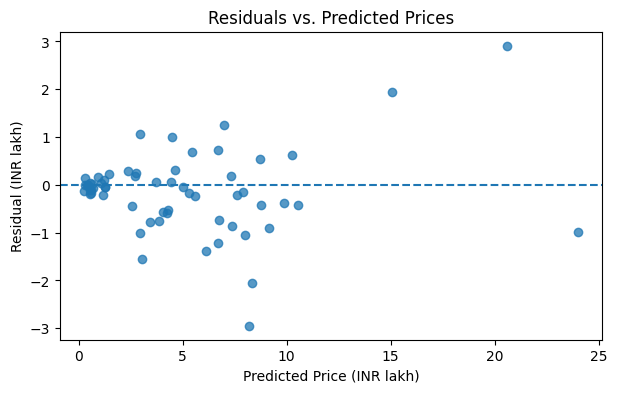

In [17]:
residuals = y_test - y_pred

plt.figure(figsize=(7, 4))
plt.scatter(y_pred, residuals, alpha=0.75)
plt.axhline(0, linestyle="--")
plt.title("Residuals vs. Predicted Prices")
plt.xlabel("Predicted Price (INR lakh)")
plt.ylabel("Residual (INR lakh)")
plt.show()

## 10. Feature Importance

For tree-based models, feature importance helps explain which variables contribute most to the predictions

,Feature,Importance
0,num__Present_Price,0.883
3,num__Vehicle_Age,0.087
1,num__Kms_Driven,0.024
5,cat__Fuel_Type_Diesel,0.004
6,cat__Fuel_Type_Petrol,0.001
2,num__Owner,0.000
10,cat__Transmission_Manual,0.000
9,cat__Transmission_Automatic,0.000
8,cat__Seller_Type_Individual,0.000
4,cat__Fuel_Type_CNG,0.000


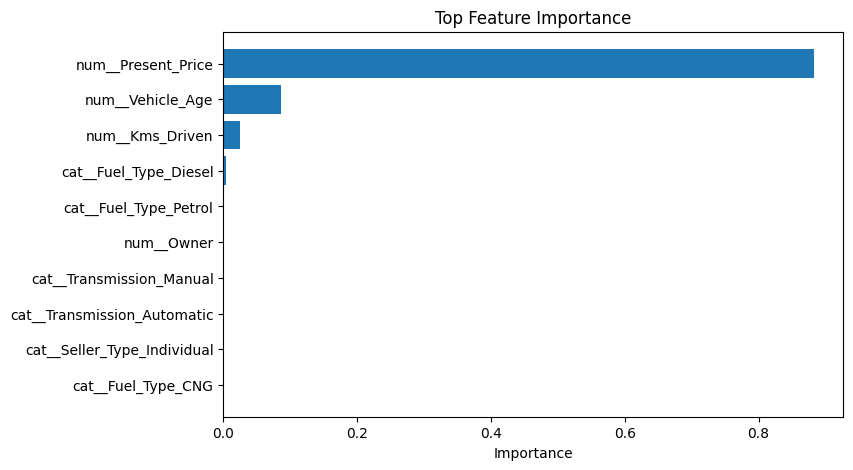

In [18]:
fitted_preprocessor = best_pipeline.named_steps["preprocessor"]
fitted_model = best_pipeline.named_steps["model"]

feature_names = fitted_preprocessor.get_feature_names_out()

if hasattr(fitted_model, "feature_importances_"):
    importance = pd.DataFrame({
        "Feature": feature_names,
        "Importance": fitted_model.feature_importances_
    }).sort_values("Importance", ascending=False)

elif hasattr(fitted_model, "coef_"):
    importance = pd.DataFrame({
        "Feature": feature_names,
        "Importance": np.abs(np.ravel(fitted_model.coef_))
    }).sort_values("Importance", ascending=False)

else:
    importance = None

if importance is not None:
    display(importance.head(10).round(3))

    plot_importance = importance.head(10).sort_values("Importance")

    plt.figure(figsize=(8, 5))
    plt.barh(plot_importance["Feature"], plot_importance["Importance"])
    plt.title("Top Feature Importance")
    plt.xlabel("Importance")
    plt.show()

## 11. Example: Dealer Price Estimate

A dealer could enter the main characteristics of a vehicle and receive an initial machine-learning price estimate

> This is only a demonstration. A real pricing system would need a much larger and more recent market dataset

In [19]:
example_car = pd.DataFrame([{
    "Present_Price": 9.5,
    "Kms_Driven": 35000,
    "Owner": 0,
    "Vehicle_Age": 4,
    "Fuel_Type": "Petrol",
    "Seller_Type": "Dealer",
    "Transmission": "Manual"
}])

estimated_price = best_pipeline.predict(example_car)[0]

print(f"Estimated Selling Price: {estimated_price:.2f} INR lakh")

Estimated Selling Price: 6.63 INR lakh


## 12. Save the Trained Model 💾 

In [23]:
import joblib
from pathlib import Path

# Create folder
Path("models").mkdir(exist_ok=True)

In [24]:
# Save the complete pipeline
joblib.dump(best_pipeline, "models/car_price_model.pkl")

['models/car_price_model.pkl']

# Conclusion

This project demonstrates an end-to-end **regression workflow** for used-car pricing:

1. Explored and visualized the dataset.
2. Created a meaningful `Vehicle_Age` feature.
3. Used a modern preprocessing and modeling pipeline.
4. Compared multiple regression algorithms with cross-validation.
5. Evaluated the selected model with **MAE, RMSE, and R²**.
6. Added feature importance and a practical dealer prediction example.

### Final results

With the selected **Gradient Boosting** model, the holdout-test results are approximately **R² = 0.968**, **MAE = 0.564 INR lakh**, and **RMSE = 0.860 INR lakh** (61 test vehicles, random_state=42). These are results on a small historical dataset, not a validated performance guarantee for today’s market.

### Business takeaway

The model can serve as a **first pricing benchmark** for a used-car dealer. However, the dataset contains only **301 records**, so a production solution should include more recent vehicles, market location, brand/model details, equipment, condition, service history, and live market prices.

### Possible next step

A simple **Streamlit app** could turn this notebook into an interactive car-price estimator for a portfolio project.